# 1단계: 실험 데이터셋 구축

`data/01_Static … 05_Dynamic` 의 모든 세션을 **Wi-Fi 스캔 1회 = 샘플 1개**로 만들고, 구역 라벨과 품질 등급을 붙여 `dataset/` 에 저장한다.
(`build_dataset.py` 와 같은 내용을 셀별로 나눈 것)

- 샘플 = Wi-Fi 스캔 1회 + 그 직전 `BLE_WIN_S` 초 동안의 BLE (peer 제외, MAC별 평균 RSSI)
- **정적(01_Static)**: 폴더 → 구역 매핑(`STATIC_ZONE`)이 정답. 세션 전체가 그 구역이므로 모든 스캔 clean.
  구역 안에서 움직이는 것은 문제없으므로 등급은 깎지 않고 `motion` 열(가속도 크기 표준편차)로만 남긴다.
- **동적(02~05)**: `zone_gt`(GT 라벨 = 핑 + IMU 보행 추정 궤적)가 구역. 핑은 구역을 옮길 때 위주로 찍었으므로 핑 사이 구간은 궤적으로 나눈다.
  GT 라벨은 스캔 2초 동안 위치 5점이 모두 한 구역 안이고 경계에서 0.3 m 이상 안쪽일 때만 붙는다.
  `zone_ping`(핑만 기준)은 참고용 열.

| 등급 | 뜻 | 쓰임 |
|---|---|---|
| clean | 정적 전부 / 동적에서 GT 라벨 있음 + 핑 사이 거리 ≤ `LONG_SEG_M` | 시험셋, 품질 필터 DB |
| noisy | 동적에서 GT 라벨 있음 + 핑 사이 거리가 긺 (궤적이 PDR 에만 기댐) | 전체 추가 DB 와 비교용 |
| drop | 동적에서 GT 라벨 없음 (경계 가까움, 스캔 중 구역 이동, 구역 밖, 첫 핑 전/마지막 핑 후 이동) | 사용 안 함 |

셀 순서: ① 설정 → ② 핑 구역 → ③ 라벨 함수 → ④ 세션 하나 처리 → ⑤ 세션 미리보기 → ⑥ 전체 실행 → ⑦ 합치기 → ⑧ BSSID·MAC 등장 표 → ⑨ 요약 표 → ⑩ 요약 그림 → ⑪ 저장

## ① 설정

In [25]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BASE = Path(r"D:\crowdsourcing")        # zone_split.py, gt_reconstruct.py 가 있는 폴더
sys.path.insert(0, str(BASE))
import zone_split as zs
from gt_reconstruct import detect_steps, load, reconstruct

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA = BASE / "data"          # 01_Static, 02_Dynamic … 폴더가 있는 곳
OUT = BASE / "dataset"        # 결과 저장 폴더
SAVE = True                   # False 면 파일을 쓰지 않고 화면에만 보여준다
PREVIEW = "02_Dynamic/4053_20261105_212102_throttleOFF_max_gt"   # ⑤ 에서 미리 볼 세션 (회차/폴더)

STATIC_ZONE = {  # 01_Static: 세션 폴더 → 구역 (사용자 기록)
    "5A16_20261105_211700_throttleOFF_max_gt": "area 1",
    "476E_20261105_211702_throttleOFF_max_gt": "area 2",
    "AA2D_20261105_211700_throttleOFF_max_gt": "area 3",
    "4053_20261105_211701_throttleOFF_max_gt": "area 4",
    "1DC2_20261105_211703_throttleOFF_max_gt": "area 5",
    "6CB7_20261105_211700_throttleOFF_max_gt": "area 6",
    "842E_20261105_211701_throttleOFF_max_gt": "area 7",
    "842E_20261105_214121_throttleOFF_max_gt": "area 8",
    "842E_20261105_214259_throttleOFF_max_gt": "area 9",
    "842E_20261105_214444_throttleOFF_max_gt": "area 10",
}
BLE_WIN_S = 3.0      # Wi-Fi 스캔 결과 시각 이전 이만큼의 BLE 를 같은 샘플로 묶는다
SNAP_M = 1.0         # 구역 밖 핑을 이 거리 안의 가장 가까운 구역으로 붙인다
MOTION_PAD_S = 1.0   # motion: 스캔 시간 앞뒤 이만큼을 더 본다
LONG_SEG_M = 5.0     # 동적: 핑 사이 거리가 이보다 긴 구간의 스캔은 noisy (PDR 궤적에만 기댐)
ZONE_ORDER = [f"area {i}" for i in range(1, 11)]
GRADE_COLOR = {"clean": "#2F5BD3", "noisy": "#9DB4EE", "drop": "#CCCCCC"}

set_dirs = sorted(p for p in DATA.iterdir() if p.is_dir() and p.name[:2].isdigit())
print({sd.name: len([p for p in sd.iterdir() if p.is_dir()]) for sd in set_dirs})

{'01_Static': 10, '02_Dynamic': 6, '03_Dynamic': 6, '04_Dynamic': 6, '05_Dynamic': 6}


## ② 핑 → 구역 (참고용 `zone_ping`)
등급에는 쓰지 않고 GT 라벨과 비교하는 참고 열을 만든다. 구역 밖에 찍힌 핑(구역 사이 틈, 문 앞)은 `SNAP_M` 안이면 가장 가까운 구역으로 붙인다.
스캔별 핑 라벨 규칙은 `zone_split.label_ping` 과 같다: 핑 전후 `STAND_S` 초 → 그 핑의 구역, 앞뒤 핑이 같은 구역이면 그 사이도 그 구역.

In [26]:
def ping_zones(gt: pd.DataFrame, zones: list):
    """(핑별 구역, 붙였는지, 붙인 거리 m). SNAP_M 밖이면 ''"""
    x, y = gt.x_m.to_numpy(), gt.y_m.to_numpy()
    pz, _ = zs.zone_of(x, y, zones)
    snapped = np.zeros(len(gt), bool)
    dist = np.zeros(len(gt))
    for i in np.where(pz == "")[0]:
        d = [(float(zs.edge_distance(x[i:i + 1], y[i:i + 1], z["poly"])[0]), z["name"]) for z in zones]
        dm, name = min(d)
        dist[i] = dm
        if dm <= SNAP_M:
            pz[i], snapped[i] = name, True
    return pz, snapped, dist


def label_ping(scan_t, span_s, pt, pz, snapped) -> pd.DataFrame:
    """zone_split.label_ping 과 같은 규칙. 구역은 붙인 핑 구역을 쓰고, 붙인 핑에 기댔는지 함께 낸다"""
    S = zs.STAND_S * 1000
    zone, snap, note = [], [], []
    for t in scan_t:
        lo, hi = t - span_s * 1000, t
        near = np.where((pt + S >= lo) & (pt - S <= hi))[0]
        if len(near):
            k = near[np.argmin(np.abs(pt[near] - t))]
            zone.append(pz[k]); snap.append(bool(snapped[k])); note.append("" if pz[k] else "핑이 구역 밖")
            continue
        prev, nxt = np.where(pt < lo)[0], np.where(pt > hi)[0]
        if len(prev) and len(nxt):
            a, b = prev[-1], nxt[0]
            if pz[a] and pz[a] == pz[b]:
                zone.append(pz[a]); snap.append(bool(snapped[a] or snapped[b])); note.append("")
            else:
                zone.append(""); snap.append(False)
                note.append("앞뒤 핑 구역이 다름" if pz[a] or pz[b] else "핑이 구역 밖")
        else:
            k = nxt[0] if len(nxt) else prev[-1]
            zone.append(pz[k]); snap.append(bool(snapped[k])); note.append("" if pz[k] else "핑이 구역 밖")
    return pd.DataFrame({"timestamp": scan_t, "zone_ping": zone, "ping_snap": snap, "ping_note": note})

## ③ 라벨 · 등급 함수
- `segment_ok`: 스캔이 걸친 핑 사이 구간이 짧은지 (≤ `LONG_SEG_M`). 짧으면 양 끝 핑에 묶여 궤적이 크게 벗어날 수 없다.
- `label_dynamic`: GT 라벨(`zs.label_gt`)이 구역. GT 라벨이 없으면 drop, 있으면 구간 길이로 clean / noisy. 첫 핑 전 / 마지막 핑 후에 걸었으면 버린다(`zs.drop_unanchored`).
- `label_static`: 폴더 매핑 구역. 모든 스캔 clean.
- `motion`: 스캔 시간(±`MOTION_PAD_S`) 동안 가속도 크기의 표준편차 (m/s²). 정지 ≈ 0.01, 손에 들고 움직이면 0.5 이상.

In [27]:
def segment_ok(scan_t, span_s, pt, seg) -> np.ndarray:
    """스캔 시간 [t - span, t] 이 걸친 핑 사이 구간이 모두 짧은지 (핑 사이 거리 <= LONG_SEG_M).
    구간 양 끝이 핑으로 고정되므로 짧은 구간에서는 PDR 궤적이 크게 벗어날 수 없다.
    첫 핑 전 / 마지막 핑 후는 핑 자리에 서 있던 구간이라 OK 로 본다 (걸었으면 drop_unanchored 가 지운다)"""
    ok = (seg["핑거리_m"] <= LONG_SEG_M).to_numpy()
    seg_of = lambda x: np.searchsorted(pt, x, side="left") - 1      # pt[i] < x <= pt[i+1] → i
    out = []
    for t in scan_t:
        i0, i1 = seg_of(t - span_s * 1000), seg_of(t)
        idx = [i for i in range(i0, i1 + 1) if 0 <= i < len(ok)]
        out.append(bool(ok[idx].all()) if idx else True)
    return np.array(out)


def label_dynamic(scan_t, track, seg, gt, zones, step_t) -> pd.DataFrame:
    """GT 라벨(핑 + PDR 궤적)이 구역. 핑은 구역을 옮길 때 위주로 찍었으므로 핑 사이 구간은 궤적으로 나눈다.
    핑 라벨(zone_ping)은 참고용 열로만 남긴다"""
    span = zs.WIFI_SPAN_S
    pz, snapped, _ = ping_zones(gt, zones)
    lab = zs.label_gt(scan_t, span, track, zones).merge(
        label_ping(scan_t, span, gt.timestamp.to_numpy(), pz, snapped), on="timestamp")
    lab = zs.drop_unanchored(lab, span, gt, step_t)
    has_gt = lab.zone_gt != ""
    ok = segment_ok(scan_t, span, gt.timestamp.to_numpy(), seg)
    lab["zone"] = lab.zone_gt
    lab["grade"] = np.select([has_gt & ok, has_gt], ["clean", "noisy"], "drop")
    lab["reason"] = np.select([has_gt & ok, has_gt], ["", "핑 사이 거리 긺"], lab.gt_note.astype(str))
    return lab[["timestamp", "x_m", "y_m", "zone", "grade", "reason", "zone_gt", "zone_ping"]]


def motion(imu: pd.DataFrame, scan_t) -> np.ndarray:
    a = imu[imu.sensor == "acc"].sort_values("timestamp")
    t = a.timestamp.to_numpy()
    m = np.sqrt(a.x ** 2 + a.y ** 2 + a.z ** 2).to_numpy()
    lo = np.searchsorted(t, scan_t - (zs.WIFI_SPAN_S + MOTION_PAD_S) * 1000)
    hi = np.searchsorted(t, scan_t + MOTION_PAD_S * 1000)
    return np.array([m[i:j].std() if j - i > 5 else np.nan for i, j in zip(lo, hi)]).round(3)


def label_static(name, scan_t, gt) -> pd.DataFrame:
    """정적 세션은 처음부터 끝까지 그 구역에 있었다 → 모든 스캔 clean"""
    zone = STATIC_ZONE[name]
    return pd.DataFrame({"timestamp": scan_t, "x_m": gt.x_m.iloc[0], "y_m": gt.y_m.iloc[0],
                         "zone": zone, "grade": "clean", "reason": "",
                         "zone_gt": zone, "zone_ping": zone})

## ④ 세션 하나 → 샘플 표
반환: 샘플 표 `s`, Wi-Fi 행 `w` (timestamp, bssid, rssi), BLE 창 `bl` (timestamp, mac, rssi 평균, n, addr_type).

In [28]:
def build_session(d: Path, set_name: str, round_no: int):
    meta, gt, imu, wifi = load(d)
    zones = zs.load_zones(str(meta["floorplan_name"]), float(meta["m_per_px"]))
    ble = pd.read_csv(d / "ble.csv", dtype={"peer": str, "mac": str})
    step_t, _ = detect_steps(imu)
    scan_t = np.sort(wifi.timestamp.unique()).astype(float)

    if set_name.startswith("01"):
        if d.name not in STATIC_ZONE:
            raise ValueError(f"정적 세션 {d.name} 의 구역이 STATIC_ZONE 에 없습니다")
        lab = label_static(d.name, scan_t, gt)
    else:
        track, _, seg, _ = reconstruct(gt, imu)
        lab = label_dynamic(scan_t, track, seg, gt, zones, step_t)

    t0 = float(meta["start_wall_ms"])
    ztype = {z["name"]: z["type"] for z in zones}
    s = lab.assign(
        session=d.name, set=set_name, round=round_no, kind="static" if round_no == 0 else "dynamic",
        device=str(meta["device_id"]), model=meta["model"],
        t_rel_s=((lab.timestamp - t0) / 1000).round(3),
        zone_type=lab.zone.map(ztype).fillna(""),
        motion=motion(imu, scan_t),
    )
    s["timestamp"] = s.timestamp.astype("int64")

    # Wi-Fi 행 / BLE 창
    w = wifi[["timestamp", "bssid", "rssi"]].copy()
    w["bssid"] = w.bssid.str.lower()
    b = ble[ble.peer.isna() | (ble.peer == "")]
    bt = b.timestamp.to_numpy()
    ble_rows = []
    for t in s.timestamp:
        m = (bt > t - BLE_WIN_S * 1000) & (bt <= t)
        if m.any():
            g = b[m].groupby("mac").agg(rssi=("rssi", "mean"), n=("rssi", "size"), addr_type=("addr_type", "first"))
            ble_rows.append(g.reset_index().assign(timestamp=t))
    bl = pd.concat(ble_rows) if ble_rows else pd.DataFrame(columns=["mac", "rssi", "n", "addr_type", "timestamp"])
    bl["rssi"] = bl.rssi.round(2)
    return s, w, bl

## ⑤ 세션 하나 미리보기
`PREVIEW` 세션의 시간에 따른 GT 구역 라벨(색: 등급)과 clean 이 아닌 이유.

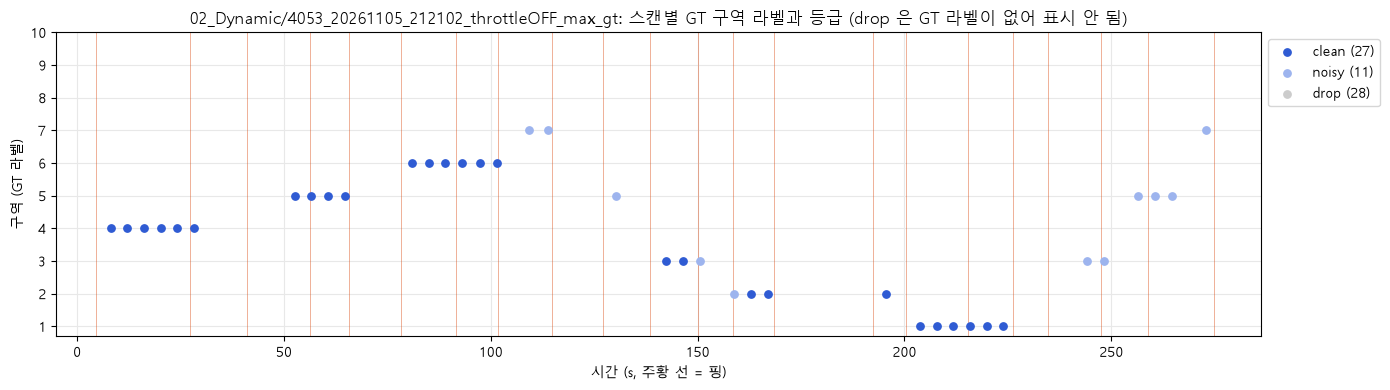

n
grade reason        
clean             27
drop  경계 가까움       5
      구역 밖         9
      스캔 중 구역 이동  13
      첫 핑 전 이동     1
noisy 핑 사이 거리 긺   11

,timestamp,x_m,y_m,zone,grade,reason,zone_gt,zone_ping,session,set,round,kind,device,model,t_rel_s,zone_type,motion
0,1793881266418,86.325,51.848,,drop,첫 핑 전 이동,,,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,4.120,,0.988
1,1793881270448,85.331,52.886,area 4,clean,,area 4,area 4,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,8.150,room,0.766
2,1793881274453,85.191,52.561,area 4,clean,,area 4,area 4,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,12.155,room,0.216
3,1793881278463,85.028,52.008,area 4,clean,,area 4,area 4,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,16.165,room,0.541
4,1793881282488,84.848,49.387,area 4,clean,,area 4,area 4,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,20.190,room,1.182
5,1793881286521,84.199,48.469,area 4,clean,,area 4,area 4,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,24.223,room,0.591
6,1793881290542,83.816,48.295,area 4,clean,,area 4,area 4,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,28.244,room,0.398
7,1793881294584,82.354,47.613,,drop,구역 밖,,,4053_20261105_212102_throttleOFF_max_gt,02_Dynamic,1,dynamic,4053,SM-S906N,32.286,,0.399


In [29]:
pv = DATA / PREVIEW
s_pv, w_pv, b_pv = build_session(pv, pv.parent.name, int(pv.parent.name[:2]) - 1)
gt_pv = pd.read_csv(pv / "gt.csv")
t0_pv = s_pv.timestamp.iloc[0] - s_pv.t_rel_s.iloc[0] * 1000

fig, ax = plt.subplots(figsize=(14, 4))
zi = {z: i for i, z in enumerate(ZONE_ORDER)}
for gname, c in GRADE_COLOR.items():
    sub = s_pv[s_pv.grade == gname]
    z = sub.zone_gt.map(zi)
    ax.scatter(sub.t_rel_s, z, s=28, color=c, label=f"{gname} ({len(sub)})", zorder=3)
for t in (gt_pv.timestamp - t0_pv) / 1000:
    ax.axvline(t, color="#D9480F", lw=0.6, alpha=0.5)
ax.set_yticks(range(len(ZONE_ORDER)), [z.replace("area ", "") for z in ZONE_ORDER])
ax.set_xlabel("시간 (s, 주황 선 = 핑)")
ax.set_ylabel("구역 (GT 라벨)")
ax.set_title(f"{PREVIEW}: 스캔별 GT 구역 라벨과 등급 (drop 은 GT 라벨이 없어 표시 안 됨)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.grid(color="#E8E8E8")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

display(s_pv.groupby(["grade", "reason"]).size().rename("n").to_frame())
display(s_pv.head(8))

## ⑥ 전체 세션 실행

In [30]:
S, W, B, rows = [], [], [], []
for sd in set_dirs:
    round_no = int(sd.name[:2]) - 1
    for d in sorted(p for p in sd.iterdir() if p.is_dir()):
        s, w, b = build_session(d, sd.name, round_no)
        S.append(s); W.append(w.assign(session=d.name)); B.append(b.assign(session=d.name))
        rows.append({"set": sd.name, "session": d.name, "device": s.device.iloc[0],
                     "zone(정적)": STATIC_ZONE.get(d.name, ""), "samples": len(s),
                     **{g: int((s.grade == g).sum()) for g in ["clean", "noisy", "drop"]},
                     "motion_median": round(float(s.motion.median()), 3)})
progress = pd.DataFrame(rows)
progress

,set,session,device,zone(정적),samples,clean,noisy,drop,motion_median
0,01_Static,1DC2_20261105_211703_throttleOFF_max_gt,1DC2,area 5,17,17,0,0,1.297
1,01_Static,4053_20261105_211701_throttleOFF_max_gt,4053,area 4,15,15,0,0,0.594
2,01_Static,476E_20261105_211702_throttleOFF_max_gt,476E,area 2,13,13,0,0,0.715
3,01_Static,5A16_20261105_211700_throttleOFF_max_gt,5A16,area 1,23,23,0,0,0.257
4,01_Static,6CB7_20261105_211700_throttleOFF_max_gt,6CB7,area 6,20,20,0,0,1.122
5,01_Static,842E_20261105_211701_throttleOFF_max_gt,842E,area 7,33,33,0,0,0.111
6,01_Static,842E_20261105_214121_throttleOFF_max_gt,842E,area 8,44,44,0,0,0.009
7,01_Static,842E_20261105_214259_throttleOFF_max_gt,842E,area 9,46,46,0,0,0.013
8,01_Static,842E_20261105_214444_throttleOFF_max_gt,842E,area 10,44,44,0,0,0.009
9,01_Static,AA2D_20261105_211700_throttleOFF_max_gt,AA2D,area 3,13,13,0,0,0.845


## ⑦ 합치기
`sample_id` 를 붙이고 Wi-Fi·BLE 행을 샘플에 연결한다. `n_wifi`, `n_ble` = 샘플당 AP 수 / BLE MAC 수.

In [31]:
samples = pd.concat(S, ignore_index=True)
samples.insert(0, "sample_id", np.arange(len(samples)))
key = samples[["sample_id", "session", "timestamp"]]
wifi = pd.concat(W).merge(key, on=["session", "timestamp"])[["sample_id", "bssid", "rssi"]]
ble = pd.concat(B).merge(key, on=["session", "timestamp"])[["sample_id", "mac", "rssi", "n", "addr_type"]]
samples = samples.merge(wifi.groupby("sample_id").size().rename("n_wifi"), on="sample_id", how="left")
samples = samples.merge(ble.groupby("sample_id").size().rename("n_ble"), on="sample_id", how="left")
samples[["n_wifi", "n_ble"]] = samples[["n_wifi", "n_ble"]].fillna(0).astype(int)
cols = ["sample_id", "set", "round", "kind", "session", "device", "model", "timestamp", "t_rel_s",
        "x_m", "y_m", "zone", "zone_type", "grade", "reason", "zone_gt", "zone_ping", "motion", "n_wifi", "n_ble"]
samples = samples[cols]

assert samples.n_wifi.sum() == len(wifi) and samples.sample_id.is_unique
print(f"샘플 {len(samples)} · Wi-Fi 행 {len(wifi)} · BLE 행 {len(ble)}")
samples.head()

샘플 2499 · Wi-Fi 행 110092 · BLE 행 216725


,sample_id,set,round,kind,session,device,model,timestamp,t_rel_s,x_m,y_m,zone,zone_type,grade,reason,zone_gt,zone_ping,motion,n_wifi,n_ble
0,0,01_Static,0,static,1DC2_20261105_211703_throttleOFF_max_gt,1DC2,SM-G996N,1793881026816,3.493,80.648,44.039,area 5,corridor,clean,,area 5,area 5,0.357,53,44
1,1,01_Static,0,static,1DC2_20261105_211703_throttleOFF_max_gt,1DC2,SM-G996N,1793881030359,7.036,80.648,44.039,area 5,corridor,clean,,area 5,area 5,0.818,61,47
2,2,01_Static,0,static,1DC2_20261105_211703_throttleOFF_max_gt,1DC2,SM-G996N,1793881033898,10.575,80.648,44.039,area 5,corridor,clean,,area 5,area 5,1.232,51,32
3,3,01_Static,0,static,1DC2_20261105_211703_throttleOFF_max_gt,1DC2,SM-G996N,1793881037471,14.148,80.648,44.039,area 5,corridor,clean,,area 5,area 5,1.013,48,54
4,4,01_Static,0,static,1DC2_20261105_211703_throttleOFF_max_gt,1DC2,SM-G996N,1793881041016,17.693,80.648,44.039,area 5,corridor,clean,,area 5,area 5,1.639,52,57


## ⑧ BSSID · BLE MAC 등장 표
ID마다 몇 회차·세션·기기·구역에서 보였는지. 이후 단계의 필터(여러 회차에 꾸준히 보이는 것만 쓰기)에 쓴다.
5A16(Tab S7)은 BLE `addr_type` 이 전부 `unknown` 이라 주소 유형 대신 이 등장 횟수로 걸러야 한다.

In [32]:
info = samples[["sample_id", "set", "session", "device", "zone"]]

def presence(df, key):
    m = df.merge(info, on="sample_id")
    return m.groupby(key).agg(sets=("set", "nunique"), sessions=("session", "nunique"),
                              devices=("device", "nunique"), samples=("sample_id", "nunique"),
                              zones=("zone", lambda z: z[z != ""].nunique()),
                              rssi_mean=("rssi", "mean"), rssi_max=("rssi", "max")).round(1)

bssids = presence(wifi, "bssid").sort_values("samples", ascending=False)
macs = presence(ble, "mac")
macs["addr_type"] = ble.groupby("mac").addr_type.first()
macs = macs.sort_values("samples", ascending=False)

print(f"BSSID {len(bssids)}개 (2회차 이상 {int((bssids.sets >= 2).sum())}) · "
      f"BLE MAC {len(macs)}개 (2회차 이상 {int((macs.sets >= 2).sum())}, 5회차 모두 {int((macs.sets >= 5).sum())})")
display(pd.DataFrame({"BSSID": bssids.sets.value_counts().sort_index(),
                      "BLE MAC": macs.sets.value_counts().sort_index()}).rename_axis("등장 회차 수"))
display(bssids.head(10))

BSSID 372개 (2회차 이상 318) · BLE MAC 1840개 (2회차 이상 859, 5회차 모두 88)


,BSSID,BLE MAC
등장 회차 수,,
1,54,981
2,25,462
3,24,238
4,36,71
5,233,88


,sets,sessions,devices,samples,zones,rssi_mean,rssi_max
bssid,,,,,,,
f0:a7:31:44:e2:78,5,34,7,2245,10,-65.0,-24
ee:74:d7:d5:da:03,5,34,7,2182,10,-68.6,-32
ee:74:d7:e5:da:03,5,34,7,2173,10,-68.6,-36
ee:74:d7:e5:c8:f0,5,34,7,2003,10,-64.3,-34
ee:74:d7:d5:c8:f0,5,34,7,1932,10,-63.5,-34
ee:74:d7:e5:c9:20,5,34,7,1883,10,-71.7,-52
f0:a7:31:44:e2:77,5,34,7,1877,10,-53.9,-5
ee:74:d7:d5:c9:20,5,33,7,1753,10,-71.1,-51
ee:74:d7:d5:ca:04,5,32,7,1724,10,-73.0,-52


## ⑨ 요약 표

In [33]:
lab = samples[samples.grade != "drop"]
zone_table = lab.pivot_table(index=["set", "grade"], columns="zone", values="sample_id", aggfunc="count", fill_value=0)
zone_table = zone_table.reindex(columns=ZONE_ORDER, fill_value=0)
zone_table["합계"] = zone_table.sum(axis=1)
print("[회차·등급별 구역 샘플 수]")
display(zone_table)

device_table = samples.groupby(["device", "model"]).agg(
    sessions=("session", "nunique"), samples=("sample_id", "size"),
    clean=("grade", lambda g: (g == "clean").sum()), noisy=("grade", lambda g: (g == "noisy").sum()),
    drop=("grade", lambda g: (g == "drop").sum()), ap_per_scan=("n_wifi", "mean"), ble_per_win=("n_ble", "mean"),
    motion_static=("motion", lambda m: m[samples.loc[m.index, "kind"] == "static"].median()),
    motion_dynamic=("motion", lambda m: m[samples.loc[m.index, "kind"] == "dynamic"].median()))
device_table["clean_%"] = (100 * device_table.clean / device_table.samples).round(1)
device_table = device_table.round(1)
print("[기기별]")
display(device_table)

reasons = samples[samples.reason != ""].groupby(["kind", "grade", "reason"]).size().rename("n")
print("[clean 이 아닌 이유]")
display(reasons.to_frame())

[회차·등급별 구역 샘플 수]


zone              area 1  area 2  area 3  area 4  area 5  area 6  area 7  area 8  area 9  area 10   합계
set        grade                                                                                      
01_Static  clean      23      13      13      15      17      20      33      44      46       44  268
02_Dynamic clean      19      23      19      16      18      19      34      36       8        6  198
           noisy       2       4       9       7       9      12      19      10       7        6   85
03_Dynamic clean      30      22      17      21      27      26      84      81      44       17  369
           noisy       2       0       1       3       5       5      25      11       3        1   56
04_Dynamic clean      25      18      40      16      16      29      71      73      48       20  356
           noisy      15       2       1       2       3       3       6       4       2        5   43
05_Dynamic clean      23      17      21      42      50      20      64      49      18       24  328
           noisy       1       1       4       4       0       1       1       2       1        1   16

[기기별]


,,sessions,samples,clean,noisy,drop,ap_per_scan,ble_per_win,motion_static,motion_dynamic,clean_%
device,model,,,,,,,,,,
1DC2,SM-G996N,5,367,233,37,97,54.3,66.2,1.3,0.7,63.5
4053,SM-S906N,5,476,273,30,173,43.6,80.6,0.6,0.6,57.4
476E,SM-X710,5,240,170,5,65,45.3,110.8,0.7,0.7,70.8
5A16,SM-T870,5,428,257,2,169,29.6,85.0,0.3,0.5,60.0
6CB7,SM-S942N,5,416,242,73,101,50.2,99.7,1.1,0.9,58.2
842E,SM-S901N,4,167,167,0,0,34.9,65.4,0.0,NaN,100.0
AA2D,SM-S911N,5,405,177,53,175,47.3,95.6,0.8,0.4,43.7


[clean 이 아닌 이유]


n
kind    grade reason         
dynamic drop  경계 가까움      267
              구역 밖        198
              마지막 핑 후 이동   22
              스캔 중 구역 이동  283
              첫 핑 전 이동     10
        noisy 핑 사이 거리 긺   200

## ⑩ 요약 그림

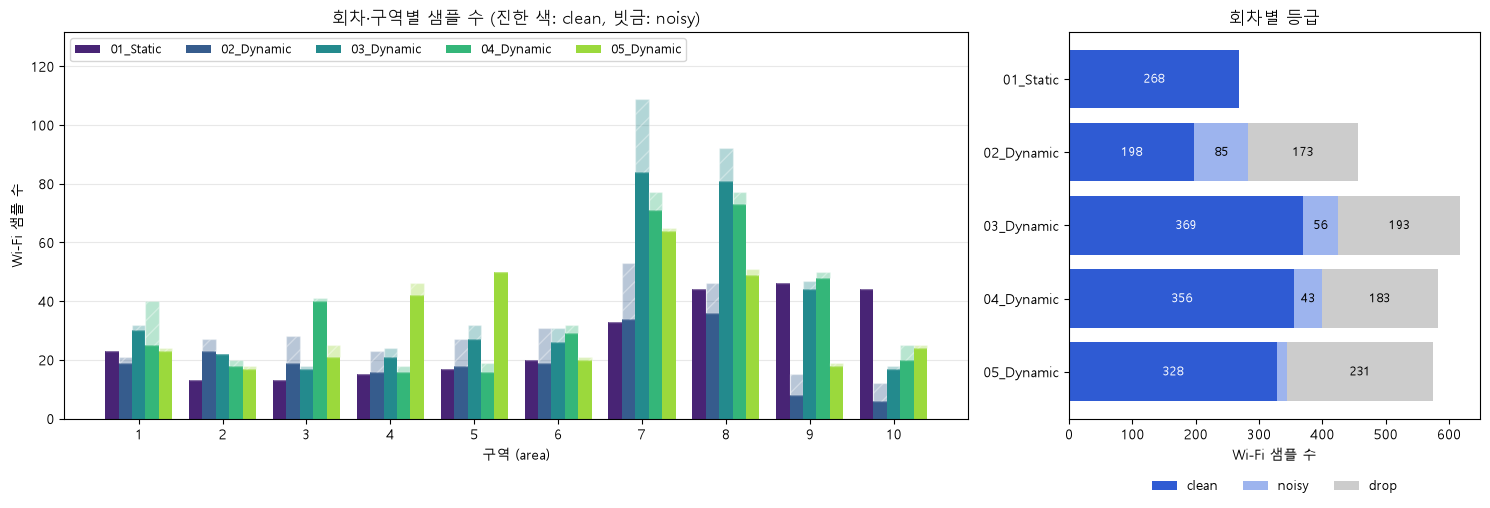

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
sets = sorted(samples.set.unique())
width = 0.8 / len(sets)
colors = plt.cm.viridis(np.linspace(0.1, 0.85, len(sets)))
x = np.arange(len(ZONE_ORDER))
for i, st in enumerate(sets):
    sub = lab[lab.set == st]
    cl = sub[sub.grade == "clean"].zone.value_counts().reindex(ZONE_ORDER, fill_value=0)
    no = sub[sub.grade == "noisy"].zone.value_counts().reindex(ZONE_ORDER, fill_value=0)
    xs = x - 0.4 + width * (i + 0.5)
    ax.bar(xs, cl, width, color=colors[i], label=st)
    ax.bar(xs, no, width, bottom=cl, color=colors[i], alpha=0.35, hatch="//", edgecolor="white")
ax.set_xticks(x, [z.replace("area ", "") for z in ZONE_ORDER])
ax.set_xlabel("구역 (area)")
ax.set_ylabel("Wi-Fi 샘플 수")
ax.set_title("회차·구역별 샘플 수 (진한 색: clean, 빗금: noisy)")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.legend(ncol=len(sets), fontsize=9, loc="upper left")
ax.grid(axis="y", color="#E8E8E8")
ax.set_axisbelow(True)

ax = axes[1]
g = samples.groupby(["set", "grade"]).size().unstack(fill_value=0).reindex(columns=["clean", "noisy", "drop"], fill_value=0)
left = np.zeros(len(g))
for col in g.columns:
    ax.barh(g.index, g[col], left=left, color=GRADE_COLOR[col], label=col)
    for yi, (l, v) in enumerate(zip(left, g[col])):
        if v >= 25:
            ax.text(l + v / 2, yi, str(v), ha="center", va="center", fontsize=9,
                    color="white" if col == "clean" else "black")
    left += g[col].to_numpy()
ax.invert_yaxis()
ax.set_title("회차별 등급")
ax.set_xlabel("Wi-Fi 샘플 수")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9, frameon=False)
fig.tight_layout()
summary_fig = fig
plt.show()

## ⑪ 저장
`SAVE = True` 일 때 `OUT` 폴더에 쓴다 (`build_dataset.py` 와 같은 파일).

In [35]:
if SAVE:
    OUT.mkdir(parents=True, exist_ok=True)
    samples.to_csv(OUT / "samples.csv", index=False, encoding="utf-8-sig")
    wifi.to_csv(OUT / "wifi.csv", index=False)
    ble.to_csv(OUT / "ble.csv", index=False)
    bssids.to_csv(OUT / "bssids.csv", encoding="utf-8-sig")
    macs.to_csv(OUT / "ble_macs.csv", encoding="utf-8-sig")
    zone_table.to_csv(OUT / "summary_zone.csv", encoding="utf-8-sig")
    device_table.to_csv(OUT / "summary_device.csv", encoding="utf-8-sig")
    summary_fig.savefig(OUT / "summary.png", dpi=130)
    for f in sorted(OUT.iterdir()):
        print(f"{f.name:20s} {f.stat().st_size / 1024:9.1f} KB")
else:
    print("SAVE = False: 저장하지 않음")

ble.csv                 8241.5 KB
ble_macs.csv              88.6 KB
bssids.csv                15.0 KB
samples.csv              400.1 KB
summary.png               67.2 KB
summary_device.csv         0.5 KB
summary_zone.csv           0.5 KB
wifi.csv                2964.0 KB
